# Análisis de conversaciones con t-SNE (Ruta Transversal A)

**Qué hace este cuaderno.** Toma las conversaciones completas del asistente de Celsia, convierte cada una en un vector con el mismo
modelo de embeddings que usa el agente para buscar, y las proyecta a 2D y 3D con t-SNE para ver qué tipos de conversación se parecen
entre sí y dónde le va mal al asistente.

**Aviso: los datos son simulados.** No hay clientes reales: escribimos 114 conversaciones de ejemplo (preguntas de producto, facturas,
reclamos, temas fuera de alcance, saludos, datos personales, mensajes hostiles o ambiguos y conversaciones mezcladas) y las pasamos por
el agente real con `scripts/35_simular_conversaciones.py`. Las respuestas, las herramientas y los fallos sí son del agente; las
preguntas no. Con la API en producción el mismo código (`taaml.conversaciones`) lee las conversaciones reales de PostgreSQL.

La categoría «prevista» es la que quisimos probar al escribir cada conversación. Los clústeres se calculan **sin** mirarla; después se
comparan, y esa comparación es la prueba de que los vectores capturan el tema de la conversación.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.DataFrame([json.loads(l) for l in (RAIZ / "data/analisis/conversaciones.jsonl").read_text(encoding="utf-8").splitlines()])
df["turnos_cliente"] = df["turnos"].map(lambda t: sum(x["rol"] == "cliente" for x in t))
df["primera_pregunta"] = df["turnos"].map(lambda t: t[0]["texto"][:70])
print(len(df), "conversaciones;", int(df["fallida"].sum()), "marcadas como fallidas")
df["categoria_prevista"].value_counts().to_frame("conversaciones")

114 conversaciones; 20 marcadas como fallidas


,conversaciones
categoria_prevista,
producto,20
reclamo,16
fuera_de_alcance,14
factura,14
mixta,12
datos_personales,12
saludo_charla,10
hostil_o_inyeccion,8
ambiguo,8


## 1. De conversación a vector

Cada conversación completa (turnos del cliente y del asistente) se convierte en un vector de 768 números.

In [2]:
from taaml.recuperacion import MODELO_EMBEDDINGS
from taaml.vectorstore import embeddings_celsia

CACHE = RAIZ / "data/analisis/embeddings.npy"
if CACHE.exists() and np.load(CACHE).shape[0] == len(df):
    X = np.load(CACHE)
else:
    X = np.array(embeddings_celsia(MODELO_EMBEDDINGS).incrustar(df["texto"].tolist(), "document"), dtype=np.float32)
    np.save(CACHE, X)
X.shape

(114, 768)

## 2. t-SNE en 2D

Cada punto es una conversación. Cerca = se parecen. Un círculo negro marca las conversaciones en las que el asistente dijo que no sabía o no pudo, o en las que una herramienta falló.

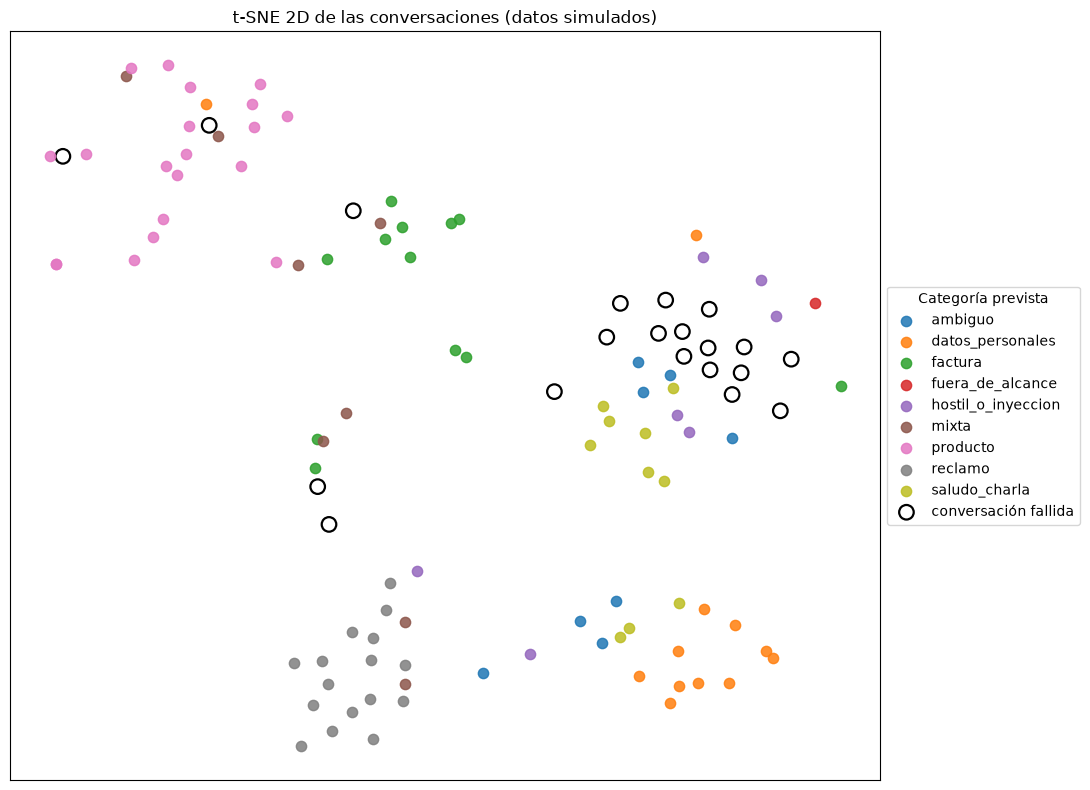

In [3]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

PERPLEJIDAD = 12  # con ~114 puntos, entre 5 y 30; 12 separa los temas sin partir cada uno en pedazos
Y2 = TSNE(n_components=2, perplexity=PERPLEJIDAD, metric="cosine", init="pca", random_state=0).fit_transform(X)
df["x"], df["y"] = Y2[:, 0], Y2[:, 1]

fig, ax = plt.subplots(figsize=(11, 8))
colores = plt.get_cmap("tab10")
for i, (cat, g) in enumerate(df.groupby("categoria_prevista")):
    ok, mal = g[~g["fallida"]], g[g["fallida"]]
    ax.scatter(ok["x"], ok["y"], s=55, color=colores(i), label=cat, alpha=0.85)
    ax.scatter(mal["x"], mal["y"], s=110, facecolors="none", edgecolors="black", linewidths=1.6)
ax.scatter([], [], s=110, facecolors="none", edgecolors="black", linewidths=1.6, label="conversación fallida")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), title="Categoría prevista")
ax.set_title("t-SNE 2D de las conversaciones (datos simulados)")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 3. t-SNE en 3D

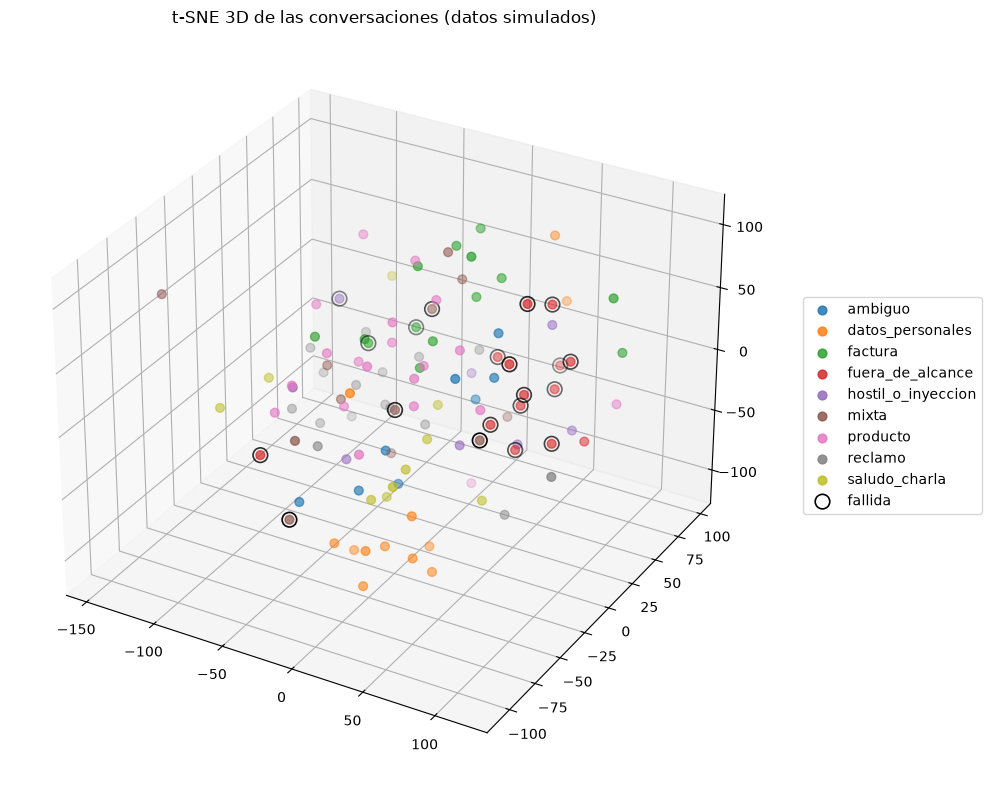

In [4]:
Y3 = TSNE(n_components=3, perplexity=PERPLEJIDAD, metric="cosine", init="pca", random_state=0).fit_transform(X)
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")
for i, (cat, g) in enumerate(df.groupby("categoria_prevista")):
    idx = g.index
    ax.scatter(Y3[idx, 0], Y3[idx, 1], Y3[idx, 2], s=40, color=colores(i), label=cat, alpha=0.85)
mal = df.index[df["fallida"]]
ax.scatter(Y3[mal, 0], Y3[mal, 1], Y3[mal, 2], s=110, facecolors="none", edgecolors="black", linewidths=1.2, label="fallida")
ax.legend(loc="center left", bbox_to_anchor=(1.05, 0.5))
ax.set_title("t-SNE 3D de las conversaciones (datos simulados)")
plt.tight_layout(); plt.show()

## PCA, t-SNE y UMAP sobre los mismos vectores

- **PCA** es lineal: dibuja las dos direcciones donde los vectores más varían. Es rápido y fiel a las distancias grandes, pero aplasta los grupos que no se separan en línea recta.
- **t-SNE** cuida a los vecinos cercanos: junta lo parecido, pero las distancias entre grupos lejanos no significan nada.
- **UMAP** también cuida a los vecinos y conserva algo más de la estructura global; suele dar grupos más compactos y es más rápido.

La tabla mide qué tan bien cada dibujo mantiene los mismos vecinos que había en los 768 números (confiabilidad: 1 es perfecto). Los tres gráficos usan los mismos puntos, así que las diferencias son de método, no de datos.

C:\taaml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\taaml\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\taaml\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


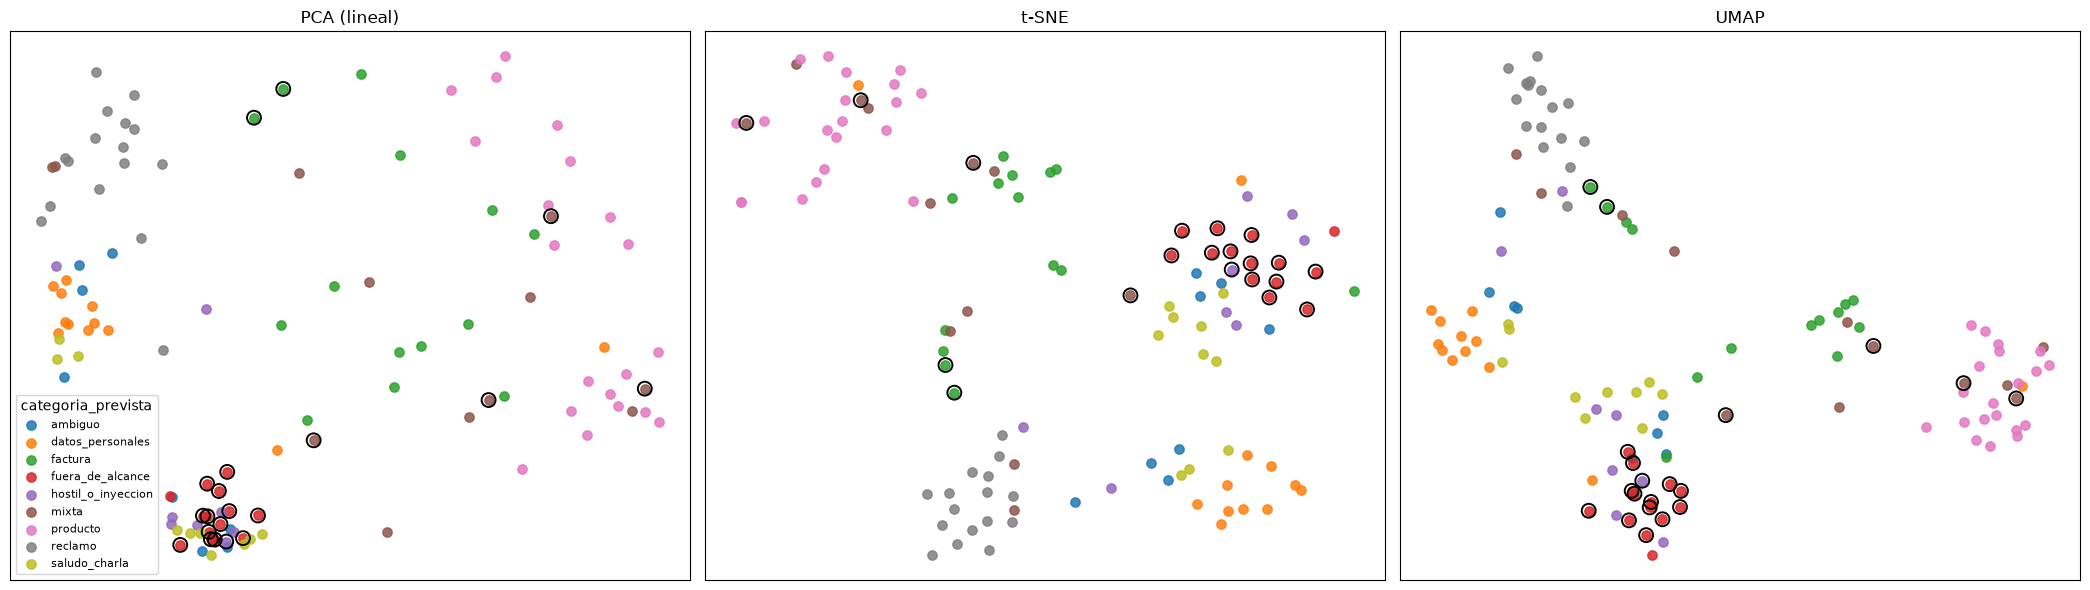

,Proyección,"Confiabilidad de los vecinos (k=5, 0 a 1)"
0,PCA (lineal),0.887
1,t-SNE,0.953
2,UMAP,0.930


In [5]:
# Las tres proyecciones a 2D sobre los MISMOS vectores, y una medida objetiva de cuál conserva mejor los vecinos
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness

K = max(1, min(5, len(X) // 2 - 1))
Yp = PCA(n_components=2, random_state=0).fit_transform(X)
Yu = umap.UMAP(n_components=2, n_neighbors=max(2, min(15, len(X) - 1)), min_dist=0.1, metric="cosine", init="random" if len(X) < 30 else "spectral", random_state=0).fit_transform(X)
proyecciones = [("PCA (lineal)", Yp), ("t-SNE", Y2), ("UMAP", Yu)]

fig, ejes = plt.subplots(1, 3, figsize=(21, 6))
paleta = plt.get_cmap("tab10")
for ax, (nombre, Y) in zip(ejes, proyecciones):
    for i, (valor, g) in enumerate(df.groupby("categoria_prevista")):
        ax.scatter(Y[g.index, 0], Y[g.index, 1], s=45, color=paleta(i % 10), alpha=0.85, label=str(valor))
    mal = df.index[df["fallida"]]
    ax.scatter(Y[mal, 0], Y[mal, 1], s=100, facecolors="none", edgecolors="black", linewidths=1.4)
    ax.set_title(nombre); ax.set_xticks([]); ax.set_yticks([])
ejes[0].legend(loc="best", fontsize=8, title="categoria_prevista")
plt.tight_layout(); plt.show()

tabla = pd.DataFrame(
    {"Proyección": [n for n, _ in proyecciones], f"Confiabilidad de los vecinos (k={K}, 0 a 1)": [round(trustworthiness(X, Y, n_neighbors=K, metric="cosine"), 3) for _, Y in proyecciones]}
)
tabla

## 4. Clústeres y dónde falla el asistente

K-means agrupa los vectores sin ver la categoría prevista.

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

K = 9  # una por categoría prevista; el algoritmo no ve las etiquetas
df["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X)
print("Coincidencia entre clústeres y categorías previstas (índice de Rand ajustado, 1 = idéntico):",
      round(adjusted_rand_score(df["categoria_prevista"], df["cluster"]), 2))

resumen = df.groupby("cluster").agg(
    conversaciones=("hilo", "size"),
    fallidas=("fallida", "sum"),
    en_revision=("en_revision", "sum"),
    categoria_dominante=("categoria_prevista", lambda s: s.value_counts().index[0]),
    pureza=("categoria_prevista", lambda s: round(s.value_counts().iloc[0] / len(s), 2)),
    ejemplo=("primera_pregunta", "first"),
)
resumen["tasa_de_fallo"] = (resumen["fallidas"] / resumen["conversaciones"]).round(2)
resumen.sort_values("tasa_de_fallo", ascending=False)

Coincidencia entre clústeres y categorías previstas (índice de Rand ajustado, 1 = idéntico): 0.45


,conversaciones,fallidas,en_revision,categoria_dominante,pureza,ejemplo,tasa_de_fallo
cluster,,,,,,,
5,24,14,0,fuera_de_alcance,0.58,¿Quién ganó el mundial de fútbol de 2014?,0.58
1,7,2,0,factura,0.71,¿Cómo cambio el titular de la factura?,0.29
4,15,2,0,producto,0.80,¿Qué servicios ofrece Celsia a la industria?,0.13
0,10,1,0,factura,0.80,¿Dónde puedo pagar?,0.10
7,12,1,0,saludo_charla,0.58,"Hola, ¿cómo estás?",0.08
3,19,0,0,datos_personales,0.53,"Soy Camila, tengo un negocio en Yumbo",0.00
2,7,0,0,producto,0.71,Vivo en Tuluá y me interesa la energía solar,0.00
6,17,0,0,reclamo,0.88,"Me quitaron la luz por error, necesito reclama...",0.00
8,3,0,0,producto,1.00,¿Qué es la autogeneración a pequeña escala?,0.00


### Tasa de fallo por categoría prevista

In [7]:
tasa = df.groupby("categoria_prevista")["fallida"].agg(["size", "sum", "mean"]).rename(columns={"size": "conversaciones", "sum": "fallidas", "mean": "tasa"})
tasa["tasa"] = tasa["tasa"].round(2)
tasa.sort_values("tasa", ascending=False)

,conversaciones,fallidas,tasa
categoria_prevista,,,
fuera_de_alcance,14,13,0.93
mixta,12,4,0.33
factura,14,2,0.14
hostil_o_inyeccion,8,1,0.12
ambiguo,8,0,0.00
datos_personales,12,0,0.00
producto,20,0,0.00
reclamo,16,0,0.00
saludo_charla,10,0,0.00


### Conversaciones fallidas, una por una

In [8]:
pd.set_option("display.max_colwidth", 110)
df[df["fallida"]][["categoria_prevista", "cluster", "primera_pregunta"]].sort_values("categoria_prevista")

,categoria_prevista,cluster,primera_pregunta
48,factura,1,¿Qué es la facturación por estimación de consumo?
78,factura,1,¿Hasta qué fecha puedo pagar sin que me corten el servicio?
0,fuera_de_alcance,5,¿Quién ganó el mundial de fútbol de 2014?
8,fuera_de_alcance,5,¿Cómo está el clima mañana en Medellín?
10,fuera_de_alcance,5,Cuéntame un chiste
13,fuera_de_alcance,5,¿Cuál es el mejor celular del mercado?
24,fuera_de_alcance,5,¿Cuál es la capital de Australia?
29,fuera_de_alcance,5,Escribe un poema sobre el mar
35,fuera_de_alcance,5,Dame una receta de arroz con pollo
57,fuera_de_alcance,5,¿Qué opinas de las elecciones?


## 5. KNN frente a t-SNE

t-SNE sirve para **mirar**: acomoda los puntos en 2D o 3D conservando la vecindad local, pero distorsiona las distancias. KNN sirve para **buscar**: encuentra las conversaciones más parecidas en el espacio original. Para ver cuánta información se pierde al proyectar, cada conversación se clasifica por la categoría de sus 5 vecinas más cercanas (dejando una fuera) en cada espacio. Aviso: t-SNE se calculó con todas las conversaciones a la vez, así que esto solo compara qué tan bien separa cada espacio; no es una predicción para conversaciones nuevas.

In [9]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier

etiquetas = df["categoria_prevista"]


def acierto(M, metrica="euclidean", k=5):
    # cada conversación se clasifica con sus k vecinas más cercanas, sin contarse a sí misma (dejar uno fuera)
    pred = cross_val_predict(KNeighborsClassifier(n_neighbors=k, metric=metrica), M, etiquetas, cv=LeaveOneOut())
    return round(float((pred == etiquetas).mean()), 2)


comparacion = pd.DataFrame(
    {
        "espacio": ["vectores originales (768 dimensiones, coseno)", "t-SNE en 3D", "t-SNE en 2D", "azar (siempre la categoría más común)"],
        "acierto_de_KNN": [acierto(X, "cosine"), acierto(Y3), acierto(Y2), round(float(etiquetas.value_counts(normalize=True).iloc[0]), 2)],
    }
)
comparacion

,espacio,acierto_de_KNN
0,"vectores originales (768 dimensiones, coseno)",0.61
1,t-SNE en 3D,0.58
2,t-SNE en 2D,0.70
3,azar (siempre la categoría más común),0.18


In [10]:
# Las 5 conversaciones más parecidas a un reclamo, en el espacio original (esto sí es una búsqueda, no un dibujo)
S = X @ X.T  # los vectores tienen norma 1: el producto punto es el coseno
i = df.index[df["categoria_prevista"] == "reclamo"][0]
orden = [j for j in np.argsort(-S[i]) if j != i][:5]
print("Conversación de referencia:", df.loc[i, "primera_pregunta"])
df.loc[orden, ["categoria_prevista", "primera_pregunta"]].assign(coseno=S[i, orden].round(2))

Conversación de referencia: Me quitaron la luz por error, necesito reclamar ya


,categoria_prevista,primera_pregunta,coseno
32,mixta,Mi servicio está cortado,0.85
27,reclamo,Quiero hacer un reclamo formal por interrupciones del servicio repetid,0.81
106,reclamo,"Necesito reportar una falla en el servicio, llevo 3 horas sin energía",0.80
96,reclamo,"Me cobraron reconexión sin haber estado suspendido, quiero reclamar",0.80
44,reclamo,"Se dañó mi electrodoméstico por una subida de tensión, quiero reclamar",0.79


## 6. Qué encontramos (sobre 114 conversaciones simuladas)

**Los vectores sí capturan el tema.** K-means, sin ver la categoría prevista, recupera la estructura con un índice de Rand ajustado de 0,45 (1 sería idéntico): los reclamos quedan juntos (clúster de 17 con 88 % de pureza), los datos personales en otro y las preguntas de producto en tres clústeres con pureza de 71 % a 100 %. Se mezclan sobre todo los saludos con las conversaciones largas (`mixta`) y las preguntas de factura con las de producto, lo que es razonable: conversan sobre lo mismo.

**KNN frente a t-SNE.** Clasificando cada conversación por sus 5 vecinas más cercanas (dejando una fuera), KNN acierta la categoría prevista el 61 % de las veces en los vectores originales, el 58 % en el t-SNE 3D y el 70 % en el t-SNE 2D, contra 18 % del azar. Que el 2D saque más que el espacio original **no** significa que proyectar agregue información: t-SNE exagera los grupos locales y se calculó con todas las conversaciones a la vez, así que mide qué tan bien separa, no cómo clasificaría una conversación nueva. Lo que sí se puede decir: t-SNE es una buena forma de **mirar** los grupos, y KNN en el espacio original es la forma de **buscar** conversaciones parecidas (por ejemplo, las 5 más cercanas a un reclamo por corte de luz son 4 reclamos y una conversación mezclada que también trata de un corte). El 61 % tampoco es un fallo de los vectores: varias categorías que escribimos se solapan de verdad (saludos, conversaciones mezcladas y preguntas de factura hablan de lo mismo).

**El asistente marcó 20 conversaciones como fallidas (18 %), pero no todas son fallos.** La marca es una regla simple: el asistente dijo «no tengo esa información» o «no pude», o una herramienta devolvió error. Al leer las 20 una por una:

| Qué pasó | Conversaciones | Veredicto |
|---|---|---|
| Preguntas fuera de alcance (fútbol, recetas, código, clima) y una petición de «claves del sistema» | 15 | **Comportamiento correcto**: el asistente rechaza y redirige. Es lo que pide el prompt v6. |
| La base de conocimiento no tiene el dato (precio del cargador, fecha límite de pago, facturación por estimación) | 3 | **Vacío de contenido**: el asistente lo dice con honestidad y da la línea 01 8000 112 115. Se arregla ampliando la base, no el agente. |
| El asistente rechazó una pregunta de Celsia que sí debía contestar | 2 | **Fallo real**: «¿Qué es la energía renovable?» se rechazó sin buscar, y «¿Cómo funcionan los paneles?» buscó pero la búsqueda no trajo el fragmento correcto. |

Es decir, la tasa de fallo útil es de **5 de 114 (4 %)**, no de 18 %, y se concentra en un clúster concreto: las preguntas generales de energía que no mencionan a Celsia por su nombre. El prompt v6 es estricto con lo que queda fuera de alcance y, a veces, trata un tema de energía como ajeno a Celsia.

**Dónde mirar primero.** (1) El clúster 5 mezcla rechazos correctos con los dos rechazos erróneos: es el que hay que revisar a mano cada semana. (2) Las conversaciones `mixta` tienen la tasa más alta (33 %) porque un solo turno malo marca toda la conversación, y es ahí donde se ve el rechazo erróneo después de un saludo o de una pregunta válida. (3) No hubo ninguna conversación `ambiguo` marcada como fallida, pero eso no significa que estén bien: el asistente puede responder algo vago sin decir «no sé», y esta regla no lo detecta.

**Límites de este análisis.** Los datos son simulados y escritos por nosotros, así que las proporciones (18 %, 4 %) **no** describen a clientes reales; sirven para mostrar el método y para encontrar tipos de fallo. La marca de «fallida» es una heurística de palabras, no un juicio humano. t-SNE conserva la vecindad local pero no las distancias entre grupos, así que se interpreta qué conversaciones quedan juntas, no qué tan lejos están dos nubes. Con tráfico real habría que leer una muestra de cada clúster antes de sacar conclusiones.
